[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IMForg-Public/imf_big_data_workshop_sti26/blob/main/notebooks/GEE%20Setup.ipynb)

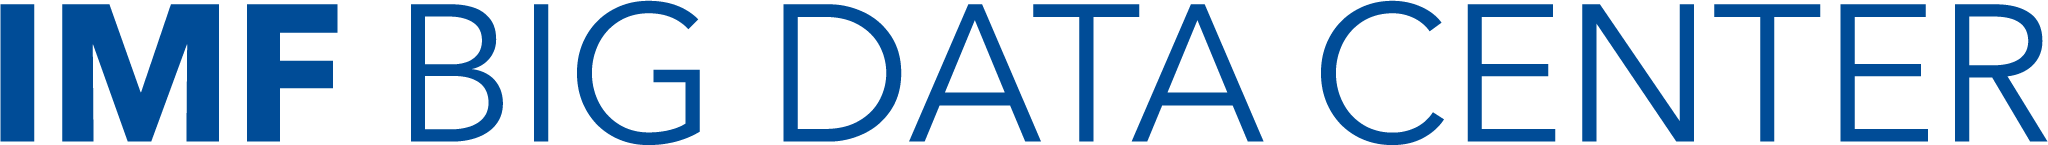


# Test Google Earth Engine (GEE) Setup



---

<br>**Contributors:** [Alessandra Sozzi](asozzi@imf.org)
<br> **Last update:** Oct-2026
<br> **Description:** This notebook checks your Google Earth Engine setup: it authenticates GEE, initialises your project, and displays an image collection on an interactive map
<br> **References:**

## Before We Start

If you haven't already, please ensure you have signed up for Google Earth Engine access and have set up a GEE project. Instructions are in the folder.

# Using Google Earth Engine

**Google Earth Engine (GEE)** is a cloud-based platform for geospatial analysis that provides access to a massive catalog of satellite imagery and other geospatial datasets, along with scalable computing power to process them.

### 🌟 Key Advantages of using GEE

- **Access to GEE's massive data catalog:** Utilize petabytes of satellite imagery and other geospatial datasets.
- **Scalable computing power:** Leverage Google's infrastructure for complex geospatial computations.
- **Integration with Python libraries:** Combine GEE with popular data science and machine learning packages.
- **Easy sharing and collaboration:** Seamlessly share analyses and scripts with others.
- **No need to download large datasets:** Perform analysis directly on the cloud.

* * *

### 🧭 GEE Workflow for This Workshop

Throughout this workshop, we will be using **Google Earth Engine**. At the start of every notebook the first thing to do is to **Load the GEE Python Library** and **Authenticate and Initialize GEE**


* * *

## **Load the GEE library, Authenticate and Initialize GEE to your project**

This step connects your notebook to your Google Earth Engine account and initializes the Earth Engine library, making it ready for use.

**You’ll be prompted to open a link, sign in with your Google account and give GEE permission.**

In [3]:
import ee

# Authenticate the Earth Engine library
ee.Authenticate()
print('Google Earth Engine has been successfully initialized.')

Google Earth Engine has been successfully initialized.


In [4]:
from google.colab import userdata

# Pull the Earth Engine project ID from Colab Secrets (set via the 🔑 panel in the sidebar)
my_project_id = userdata.get('gee_project_id')
ee.Initialize(project=my_project_id)

In [5]:
print(ee.String('Hello from the Earth Engine servers!').getInfo())

Hello from the Earth Engine servers!


# Load an image collection and display it on a Map

For this, we’ll use **`geemap`**, a powerful Python package for **interactive geospatial analysis and visualization** with Google Earth Engine. It is built on top of **`ipyleaflet`** and **`ipywidgets`**, which make it easy to create dynamic maps and visualize GEE data directly within a **Jupyter Notebook** or **Google Colab** environment.  

In [6]:
import geemap

dataset = ee.ImageCollection('ESA/WorldCover/v100').first()

visualization = {
    'bands': ['Map'],
    'min': 10,
    'max': 100,
    'palette': [
        '#006400', '#ffbb22', '#ffff4c', '#f096ff', '#fa0000',
        '#b4b4b4', '#f0f0f0', '#0064c8', '#0096a0', '#00cf75', '#fae6a0'
    ]
}

m = geemap.Map(basemap='HYBRID')
m.center_object(dataset)
m.add_layer(dataset, visualization, 'Landcover')
# Define legend dictionary
legend_dict = {
    'Tree cover': '#006400',
    'Shrubland': '#ffbb22',
    'Grassland': '#ffff4c',
    'Cropland': '#f096ff',
    'Built-up': '#fa0000',
    'Bare / sparse vegetation': '#b4b4b4',
    'Snow and ice': '#f0f0f0',
    'Permanent water bodies': '#0064c8',
    'Herbaceous wetland': '#0096a0',
    'Mangroves': '#00cf75',
    'Moss and lichen': '#fae6a0'
}

# Add the legend to the map
m.add_legend(title="ESA WorldCover 2020", legend_dict=legend_dict)
m

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

# Great, you are done!

You have successfully set up GEE and accessed its data collection and computing power. You are now ready to proceed with this workshop!